## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


In [136]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python
import textwrap

In [137]:
df=pd.read_csv("amz_uk_price_prediction_dataset.csv.zip", compression='zip')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [138]:
frequency_df=df.category.value_counts().reset_index().sort_values(by="count", ascending=False)
print(f"The top 5 most listed product categories are: {list(frequency_df.head(5).category)}")

The top 5 most listed product categories are: ['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories', 'Bath & Body', 'Birthday Gifts']


2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

Text(0.5, 1.0, 'Top 5 most listed product categories')

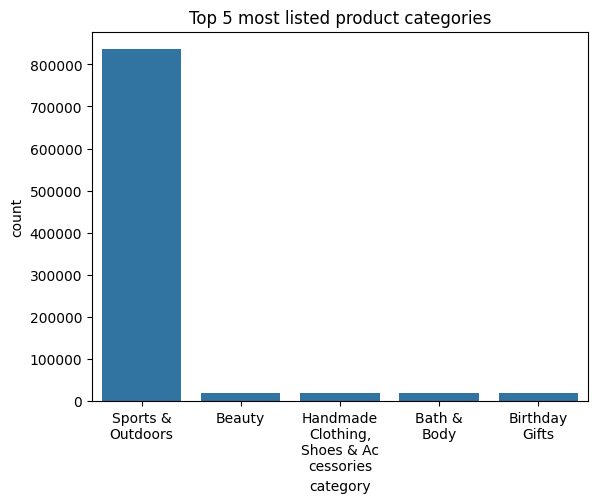

In [139]:
sns.barplot(
    data=frequency_df.head(5),
    x="category",
    y="count",
)
labels = [textwrap.fill(label, width=10) for label in frequency_df.head(5).category]
plt.xticks(ticks=range(len(labels)), labels=labels, rotation=0)
plt.title("Top 5 most listed product categories")

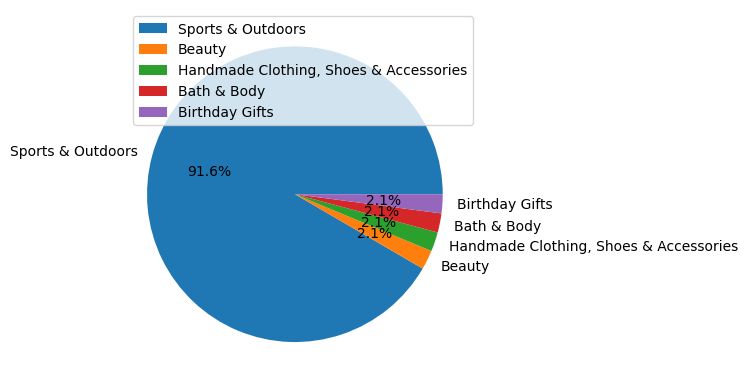

The most dominant category is: Sports & Outdoors.


In [140]:
frequency_df.head(5).plot.pie(y='count', autopct='%1.1f%%', labels=frequency_df.head(5).category)
plt.show()
print(f"The most dominant category is: {frequency_df.iloc[0].category}.")

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [141]:
#First, I'll clean up all the prices that are 0. I'll replace them with NaN values, and then drop those rows from the dataset.
df['price'] = df['price'].replace(0, np.nan)

In [142]:
print(f"The mean price of the products is: {df.price.mean():.2f} £.\nThe median price of products is: {df.price.median():.2f} £.\nThe mode price of products is: {df.price.mode()[0]:.2f} £.\n")
print(f"The average price of products is: {df.price.mean():.2f} £, when compared to the mode: {df.price.mode()[0]:.2f} £, is higher. This means that the distribution of prices is right-skewed, with a long tail of higher-priced products.")

The mean price of the products is: 89.24 £.
The median price of products is: 19.09 £.
The mode price of products is: 9.99 £.

The average price of products is: 89.24 £, when compared to the mode: 9.99 £, is higher. This means that the distribution of prices is right-skewed, with a long tail of higher-priced products.


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [143]:
print(f"The variance of the price variable is: {df.price.var():,.2f} £.")
print(f"The standard deviation of the price variable is: {df.price.std():,.2f} £.")
print(f"The range of the price variable is: ({df.price.max():,.2f} £ - {df.price.min():,.2f} £).")
print(f"The interquartile range of the price variable is: ({df.price.quantile(0.75)} £ - {df.price.quantile(0.25):,.2f} £).")
print(f"\nThe variance is significantly higher than the mean, which indicates that there is a wide spread of prices in the dataset. The standard deviation is also quite high, which further confirms that there is a lot of variability in the prices. The range of prices is quite large, with some products being priced very low and others being priced very high. The interquartile range is also quite large, which suggests that there are many products with prices that are significantly different from the median price.\nAll of this is also confirmed when checking the skewness: {float(df.price.skew()):.2f} which is significantly higher than 0 (indicating right skewness).")

The variance of the price variable is: 119,446.40 £.
The standard deviation of the price variable is: 345.61 £.
The range of the price variable is: (100,000.00 £ - 0.01 £).
The interquartile range of the price variable is: (45.99 £ - 9.99 £).

The variance is significantly higher than the mean, which indicates that there is a wide spread of prices in the dataset. The standard deviation is also quite high, which further confirms that there is a lot of variability in the prices. The range of prices is quite large, with some products being priced very low and others being priced very high. The interquartile range is also quite large, which suggests that there are many products with prices that are significantly different from the median price.
All of this is also confirmed when checking the skewness: 27.49 which is significantly higher than 0 (indicating right skewness).


3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

<Axes: xlabel='price', ylabel='Count'>

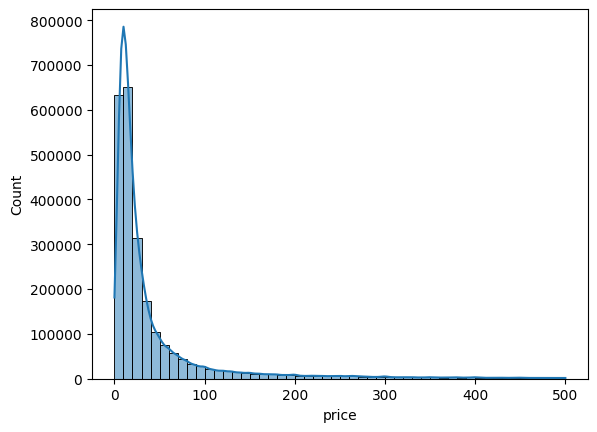

In [144]:
#Since its hard to read the histogram with the outliers, I'll set a price threshold of 500£ to focus on the distribution of the majority of products.
sns.histplot(df[df.price < 500].price, bins=50, kde=True)

Text(0.5, 1.0, 'Distribution of Product Prices (Log Scale)')

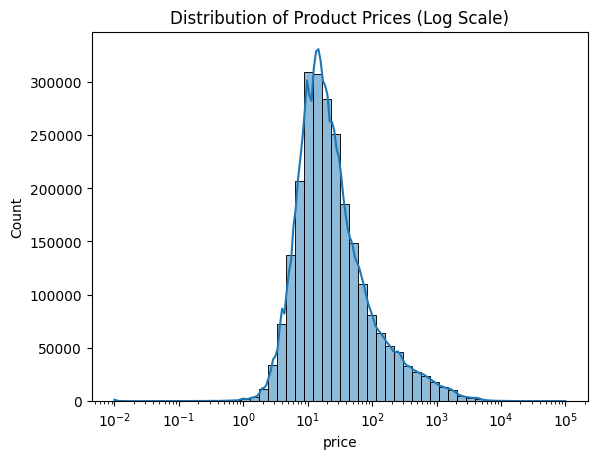

In [145]:
#Since the distribution is right-skewed, I'll plot the histogram with a log scale to better visualize the distribution of prices.
sns.histplot(df.price, bins=50, kde=True,log_scale=True)
plt.title("Distribution of Product Prices (Log Scale)")

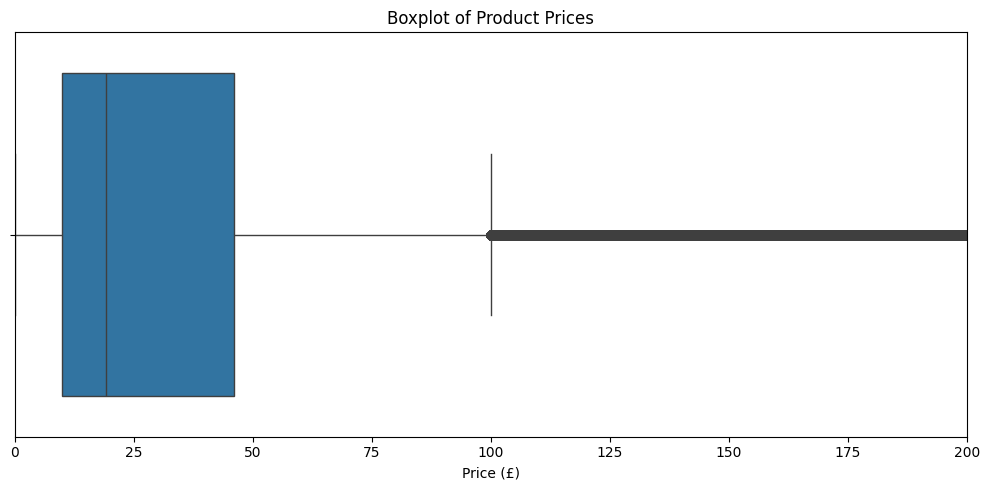

Products priced above £99.99 are considered outliers.
There are 327688 products priced significantly higher than the rest.


In [157]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['price'])
plt.title("Boxplot of Product Prices")
plt.xlabel("Price (£)")
plt.xlim(0, 200)
plt.tight_layout()
plt.show()

q75 = df['price'].quantile(0.75)
iqr = q75 - df['price'].quantile(0.25)
outlier_threshold = q75 + 1.5 * iqr
outliers = df[df['price'] > outlier_threshold]

print(f"Products priced above £{outlier_threshold:.2f} are considered outliers.")
print(f"There are {len(outliers)} products priced significantly higher than the rest.")

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [165]:
df.loc[df['reviews'] == 0, 'stars'] = np.nan

In [166]:
print(f"The mean of stars is: {df.stars.mean():.2f}.\nThe median of stars is: {df.stars.median():.2f}.\nThe mode of stars is: {df.stars.mode()[0]:.2f}.\n")

The mean of stars is: 4.32.
The median of stars is: 4.40.
The mode of stars is: 4.50.



Text(0.5, 0, 'Stars')

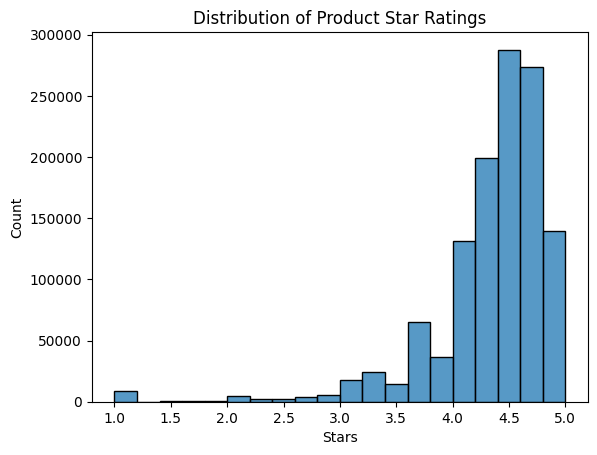

In [171]:
sns.histplot(df.stars.dropna(),bins=20)
plt.title("Distribution of Product Star Ratings")
plt.xlabel("Stars")

In [173]:
print(f"Customers tend to give high ratings, with a mean of {df.stars.mean():.2f} and a median of {df.stars.median():.2f}. The distribution is right-skewed, as indicated by the positive skewness value of {df['stars'].skew():.2f}, which suggests that there are more products with higher star ratings than lower ones.")

Customers tend to give high ratings, with a mean of 4.32 and a median of 4.40. The distribution is right-skewed, as indicated by the positive skewness value of -2.38, which suggests that there are more products with higher star ratings than lower ones.


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [174]:
print(f"The variance of the stars rating variable is: {df.stars.var():.2f}.\nThe standard deviation of the stars rating variable is: {df.stars.std():.2f}.\nThe range of the stars rating variable is: ({df.stars.max():.2f} - {df.stars.min():.2f}).\nThe interquartile range of the stars rating variable is: ({df.stars.quantile(0.75):.2f} - {df.stars.quantile(0.25):.2f}).\n")

The variance of the stars rating variable is: 0.31.
The standard deviation of the stars rating variable is: 0.56.
The range of the stars rating variable is: (5.00 - 1.00).
The interquartile range of the stars rating variable is: (4.60 - 4.10).



In [175]:
print(f"""
With a standard deviation of {df.stars.std():.2f} and an IQR of {df.stars.quantile(0.75):.2f} on a 0-5 scale, 
customer ratings are fairly consistent. Most products fall within a narrow 
range of high ratings, suggesting that customers generally agree on product 
quality rather than being polarized in their feedback.
""")


With a standard deviation of 0.56 and an IQR of 4.60 on a 0-5 scale, 
customer ratings are fairly consistent. Most products fall within a narrow 
range of high ratings, suggesting that customers generally agree on product 
quality rather than being polarized in their feedback.



3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [183]:
print(f"Skewness of stars: {df.stars.dropna().skew():.2f}")
print("""
Since the skewness is < 0, the distribution of star ratings is left-skewed, 
indicating that there are more products with higher star ratings than lower ones.""")

Skewness of stars: -2.38

Since the skewness is < 0, the distribution of star ratings is left-skewed, 
indicating that there are more products with higher star ratings than lower ones.


4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

Text(0.5, 0, 'Stars')

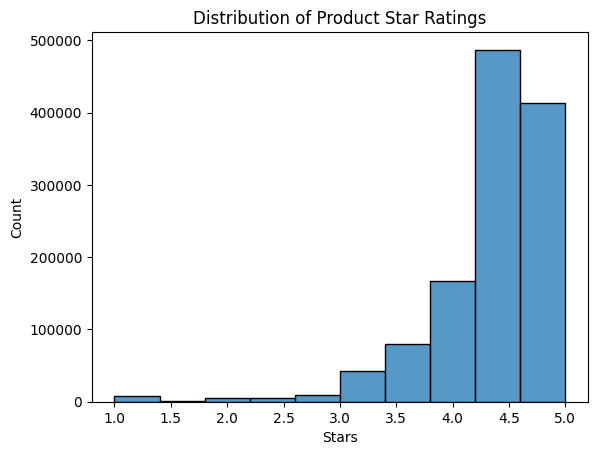

In [189]:
sns.histplot(df.stars.dropna(),bins=10)
plt.title("Distribution of Product Star Ratings")
plt.xlabel("Stars")

In [190]:
print(f"The most common rating is: {df.stars.mode()[0]:.2f} stars.")

The most common rating is: 4.50 stars.
